# **III. Câu hỏi Machine Learning**

### **3.1. Dự đoán ứng dụng đạt ngưỡng phổ biến (Installs >= 1.000.000)**

**Người thực hiện:** Văn Đình Hiếu

**Câu hỏi:** Nếu chỉ dùng các thông tin mô tả sản phẩm và cấu hình kỹ thuật có sẵn từ đầu (không dùng `Reviews`, `Rating`), mô hình học máy có phân loại được ứng dụng đạt `Installs` >= 1.000.000 tốt hơn baseline đoán lớp đa số hay không, và những đặc trưng nào quan trọng nhất?

**Động lực:** Giúp nhà phát triển ước lượng khả năng một ứng dụng đạt mốc triệu lượt tải dựa trên danh mục, thể loại, giá bán, dung lượng và phiên bản Android hỗ trợ, thay vì dựa vào các chỉ số chỉ xuất hiện sau khi ứng dụng đã có người dùng.

#### **1. Bài toán, nhãn và tránh rò rỉ dữ liệu**

- **Bài toán:** Phân loại nhị phân với `y = 1` nếu cận dưới `Installs` >= 1.000.000, ngược lại `y = 0`.
- **Đặc trưng sử dụng:** `Category`, `Genres`, `Content Rating`, `Price`, `Size_MB`, `Size_varies`, phiên bản Android tối thiểu (`Android_min`, `Android_varies`), cùng độ dài tên app (`Name_len`, `Name_words`).
- **Các cột bị loại để tránh rò rỉ dữ liệu:** `Reviews` (tương quan Spearman 0,97 với `Installs`), `Rating` (chỉ có sau khi có người dùng), `Last Updated` và `Current Ver` (phát sinh trong quá trình vận hành sau này), và `Installs` (dùng tạo nhãn). Cột `App` chỉ dùng làm khóa chia nhóm.
- **Loại cột `Type`:** Kiểm tra cho thấy `Free` khớp hoàn toàn với `Price = 0` và `Paid` khớp hoàn toàn với `Price > 0`, nên bỏ `Type` để tránh trùng lặp thông tin.
- Giữ toàn bộ 10.357 dòng đã làm sạch (không lọc trùng tên app) vì bước chia tập theo nhóm `App` sẽ đảm bảo các dòng cùng tên không bị tách sang cả train và test.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    GridSearchCV, GroupKFold, GroupShuffleSplit, cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, roc_auc_score, roc_curve
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

project_path = str(PROJECT_ROOT.resolve())
if project_path not in sys.path:
    sys.path.insert(0, project_path)

import src.preprocessing as preprocessing

# Đọc và tiền xử lý dữ liệu gốc
apps_raw = pd.read_csv(PROJECT_ROOT / "data/raw/googleplaystore.csv")
apps, cleaning_report = preprocessing.preprocess_apps(apps_raw)
display(cleaning_report)

# Tạo nhãn phân loại nhị phân
apps["y"] = (apps["Installs"] >= 1_000_000).astype(int)
conflict = (apps.groupby("App")["y"].nunique() > 1).sum()

print(f"Số dòng: {len(apps):,}")
print(f"Số tên app phân biệt: {apps['App'].nunique():,}")
print(f"Tỷ lệ lớp dương (>= 1M): {apps['y'].mean():.3f}")
print(f"Số tên app bị khác nhãn giữa các dòng: {conflict}")

# Kiểm tra Type có trùng hoàn toàn với Price > 0 không
type_price = pd.crosstab(apps["Type"], apps["Price"] > 0)
type_price.columns = ["Price == 0", "Price > 0"]
display(type_price)

,Step,Rows before,Removed,Rows after
0,Remove malformed rows,10841,1,10840
1,Remove exact duplicates,10840,483,10357


Số dòng: 10,357
Số tên app phân biệt: 9,659
Tỷ lệ lớp dương (>= 1M): 0.391
Số tên app bị khác nhãn giữa các dòng: 6


,Price == 0,Price > 0
Type,,
Free,9592,0
Paid,0,765


Tỷ lệ lớp 1 chiếm 39,1%. Tuy không quá mất cân bằng nhưng nếu chỉ dùng baseline đoán lớp đa số (lớp 0) thì Accuracy vẫn đạt khoảng 61% dù không dự đoán đúng được app phổ biến nào. Có 6 tên app bị khác nhãn giữa các dòng, tỷ lệ rất nhỏ nên không ảnh hưởng đáng kể.

In [2]:
# Tách phiên bản Android tối thiểu và cờ Varies with device
android_text = apps["Android Ver"].astype("string")
android_min = android_text.str.extract(r"^(\d+(?:\.\d+)?)")[0].astype(float)
android_varies = (android_text == "Varies with device").astype(float)

X = pd.DataFrame({
    "Category": apps["Category"].astype(str),
    "Genres": apps["Genres"].astype("string").fillna(""),
    "Content Rating": apps["Content Rating"].astype(str),
    "Price": apps["Price"],
    "Size_MB": apps["Size_MB"],
    "Size_varies": apps["Size_varies"].astype(float),
    "Android_min": android_min,
    "Android_varies": android_varies,
    "Name_len": apps["App"].str.len(),
    "Name_words": apps["App"].str.split().str.len()
})
y = apps["y"]
groups = apps["App"]

CAT_COLS = ["Category", "Content Rating"]
NUM_COLS = [
    "Price", "Size_MB", "Size_varies", "Android_min",
    "Android_varies", "Name_len", "Name_words"
]
TECH_COLS = [
    "Size_MB", "Size_varies", "Android_min", "Android_varies",
    "Name_len", "Name_words"
]

print("Các cột bị loại: Reviews, Rating, Installs, Last Updated, Current Ver (và Type do trùng Price).")
display(X.isna().sum().rename("Số giá trị thiếu").to_frame().T)

Các cột bị loại: Reviews, Rating, Installs, Last Updated, Current Ver (và Type do trùng Price).


,Category,Genres,Content Rating,Price,Size_MB,Size_varies,Android_min,Android_varies,Name_len,Name_words
Số giá trị thiếu,0,0,0,0,1526,0,1223,2,0,0


`Size_MB` thiếu 1.526 dòng (đều là `"Varies with device"`) và `Android_min` thiếu 1.223 dòng (do `"Varies with device"` hoặc thiếu dữ liệu). Hai cột này sẽ được điền bằng trung vị bên trong Pipeline (chỉ học từ tập train), đi kèm hai cột cờ `Size_varies` và `Android_varies`.

#### **2. Chia dữ liệu theo nhóm**

Vì nhiều dòng có thể thuộc cùng một ứng dụng, nhóm dùng `GroupShuffleSplit` (80% train, 20% test) theo cột `App` để tránh rò rỉ giữa hai tập. Tập test chỉ dùng đúng một lần ở bước đánh giá cuối.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

shared_names = set(g_train) & set(g_test)
print(f"Tập train: {len(X_train):,} dòng ({g_train.nunique():,} tên app), tỷ lệ lớp 1 = {y_train.mean():.3f}")
print(f"Tập test:  {len(X_test):,} dòng ({g_test.nunique():,} tên app), tỷ lệ lớp 1 = {y_test.mean():.3f}")
print(f"Số tên app trùng giữa train và test: {len(shared_names)}")

Tập train: 8,291 dòng (7,727 tên app), tỷ lệ lớp 1 = 0.392
Tập test:  2,066 dòng (1,932 tên app), tỷ lệ lớp 1 = 0.388
Số tên app trùng giữa train và test: 0


Hai tập không bị trùng tên app nào và tỷ lệ lớp dương gần như tương đương nhau (0,392 và 0,388).

#### **3. Pipeline, so sánh mô hình và tinh chỉnh**

Toàn bộ bước tiền xử lý nằm trong `Pipeline`. Các cột số được điền trung vị và chuẩn hóa. `Category` và `Content Rating` dùng `OneHotEncoder`. `Genres` dùng `CountVectorizer` ở chế độ nhị phân với bộ tách nhãn dùng chung. Mỗi nhãn thể loại xuất hiện ở ít nhất 20 bản ghi của tập huấn luyện tạo một cột chỉ báo. Một ứng dụng có thể bật nhiều cột thể loại. Từ vựng và các phép biến đổi được học trên phần huấn luyện của từng lượt kiểm định chéo.

Ba mô hình được đem ra so sánh.

1. **Baseline:** `DummyClassifier(strategy="most_frequent")`.
2. **Logistic Regression:** mô hình tuyến tính, tinh chỉnh tham số điều chuẩn `C`.
3. **HistGradientBoosting:** mô hình cây tăng cường độ dốc, tinh chỉnh `learning_rate`, `max_depth`, `min_samples_leaf`.

Việc tinh chỉnh dùng `GridSearchCV` kết hợp `GroupKFold(5)` theo `App` trên tập train, tối ưu theo chỉ số ROC-AUC.

In [4]:
def make_pipe(model, num_cols, cat_cols, use_genres=True):
    num_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler())
    ])
    transformers = [("num", num_pipe, num_cols)]
    if cat_cols:
        enc = OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False)
        transformers.append(("cat", enc, cat_cols))
    if use_genres:
        genre_encoder = CountVectorizer(
            analyzer=preprocessing.split_genres, binary=True, min_df=20
        )
        transformers.append(("genre", genre_encoder, "Genres"))

    prep = ColumnTransformer(transformers, sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])


cv = GroupKFold(n_splits=5)

# 1. Baseline đoán lớp đa số
dummy_pipe = make_pipe(DummyClassifier(strategy="most_frequent"), NUM_COLS, CAT_COLS)
dummy_pipe.fit(X_train, y_train)
dummy_cv = cross_val_score(dummy_pipe, X_train, y_train, groups=g_train, cv=cv, scoring="roc_auc").mean()

# 2. Logistic Regression
log_pipe = make_pipe(LogisticRegression(max_iter=2000), NUM_COLS, CAT_COLS)
log_search = GridSearchCV(log_pipe, {"model__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="roc_auc")
log_search.fit(X_train, y_train, groups=g_train)

# 3. HistGradientBoosting
hgb_pipe = make_pipe(HistGradientBoostingClassifier(random_state=42), NUM_COLS, CAT_COLS)
hgb_grid = {
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [3, None],
    "model__min_samples_leaf": [20, 50]
}
hgb_search = GridSearchCV(hgb_pipe, hgb_grid, cv=cv, scoring="roc_auc")
hgb_search.fit(X_train, y_train, groups=g_train)

cv_scores = pd.DataFrame([
    {"Mô hình": "Dummy (lớp đa số)", "Train CV ROC-AUC": dummy_cv, "Tham số tốt nhất": "-"},
    {"Mô hình": "Logistic Regression", "Train CV ROC-AUC": log_search.best_score_, "Tham số tốt nhất": log_search.best_params_},
    {"Mô hình": "HistGradientBoosting", "Train CV ROC-AUC": hgb_search.best_score_, "Tham số tốt nhất": hgb_search.best_params_},
]).set_index("Mô hình")

with pd.option_context("display.max_colwidth", None):
    display(cv_scores.round(4))

models = {
    "Dummy (lớp đa số)": dummy_pipe,
    "Logistic Regression": log_search,
    "HistGradientBoosting": hgb_search
}
best_name = "HistGradientBoosting" if hgb_search.best_score_ >= log_search.best_score_ else "Logistic Regression"
best_est = models[best_name]
print(f"Mô hình tốt nhất theo CV trên train: {best_name}")

# Huấn luyện thêm mô hình đối chứng chỉ dùng đặc trưng kỹ thuật để so sánh ở bước 6
tech_pipe = make_pipe(
    HistGradientBoostingClassifier(random_state=42),
    TECH_COLS, [], use_genres=False
)
tech_pipe.set_params(**hgb_search.best_params_)
tech_pipe.fit(X_train[TECH_COLS], y_train)

,Train CV ROC-AUC,Tham số tốt nhất
Mô hình,,
Dummy (lớp đa số),0.5000,-
Logistic Regression,0.8349,{'model__C': 10}
HistGradientBoosting,0.8537,"{'model__learning_rate': 0.1, 'model__max_depth': None, 'model__min_samples_leaf': 20}"


Mô hình tốt nhất theo CV trên train: HistGradientBoosting


Cả hai mô hình đều đạt ROC-AUC cao hơn mô hình cơ sở (0,5000) khi kiểm định chéo trên tập huấn luyện. Logistic Regression đạt 0,8349 và HistGradientBoosting đạt 0,8537. HistGradientBoosting được chọn để phân tích lỗi và giải thích đặc trưng.

#### **4. Đánh giá trên tập test**

Nhóm đánh giá bằng ROC-AUC (không phụ thuộc ngưỡng cắt), PR-AUC và F1 (tập trung vào khả năng bắt đúng lớp app phổ biến). Accuracy chỉ ghi thêm để đối chiếu, vì baseline đoán toàn bộ là lớp 0 vẫn đạt Accuracy 0,61 nhưng F1 bằng 0.

In [5]:
proba = {}
pred = {}
rows = []

for name, est in models.items():
    p = est.predict_proba(X_test)[:, 1]
    y_hat = (p >= 0.5).astype(int)
    proba[name] = p
    pred[name] = y_hat
    rows.append({
        "Mô hình": name,
        "ROC-AUC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "F1": f1_score(y_test, y_hat),
        "Accuracy": accuracy_score(y_test, y_hat)
    })

test_scores = pd.DataFrame(rows).set_index("Mô hình")
display(test_scores.round(4))
print(f"Tỷ lệ lớp dương trên tập test: {y_test.mean():.3f}")

# Lưu kết quả mô hình đối chứng kỹ thuật
p_tech = tech_pipe.predict_proba(X_test[TECH_COLS])[:, 1]
tech_roc_auc = roc_auc_score(y_test, p_tech)
tech_pr_auc = average_precision_score(y_test, p_tech)

,ROC-AUC,PR-AUC,F1,Accuracy
Mô hình,,,,
Dummy (lớp đa số),0.5000,0.3877,0.0000,0.6123
Logistic Regression,0.8432,0.7714,0.6727,0.7730
HistGradientBoosting,0.8575,0.7941,0.7107,0.7880


Tỷ lệ lớp dương trên tập test: 0.388


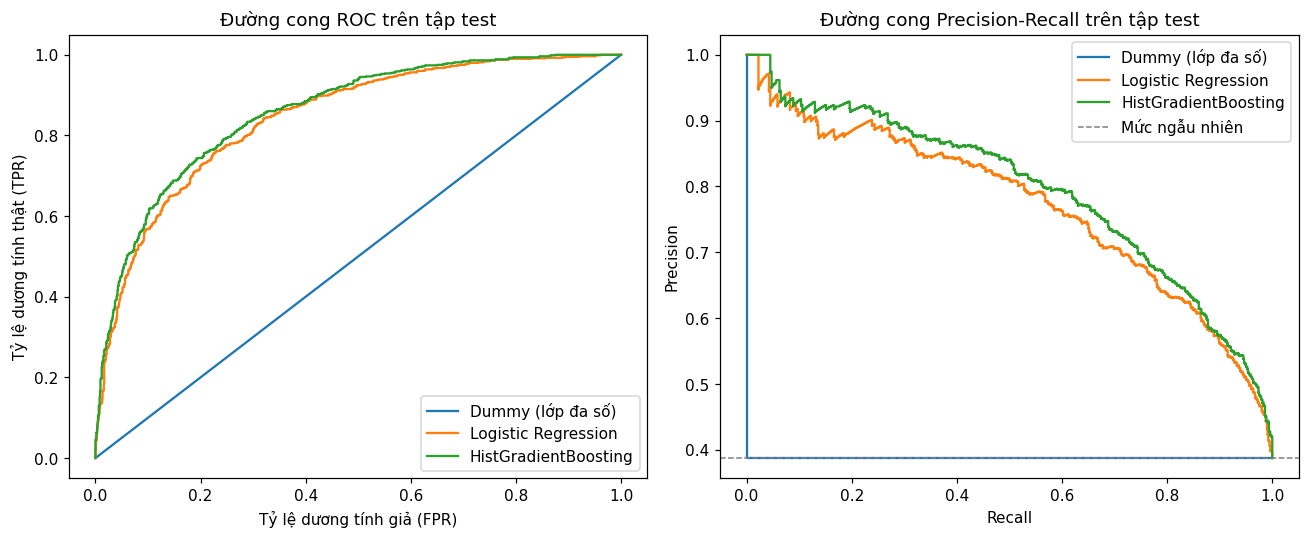

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].step(rec, prec, where="post", label=name)

axes[0].set_title("Đường cong ROC trên tập test")
axes[0].set_xlabel("Tỷ lệ dương tính giả (FPR)")
axes[0].set_ylabel("Tỷ lệ dương tính thật (TPR)")
axes[0].legend()

axes[1].set_title("Đường cong Precision-Recall trên tập test")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", linewidth=1, label="Mức ngẫu nhiên")
axes[1].legend()

plt.tight_layout()
plt.show()

- HistGradientBoosting đạt ROC-AUC / PR-AUC / F1 lần lượt là 0,8575 / 0,7941 / 0,7107. Logistic Regression đạt 0,8432 / 0,7714 / 0,6727. Mô hình cơ sở đoán lớp đa số đạt 0,5000 / 0,3877 / 0,0000.
- So với mô hình cơ sở, HistGradientBoosting tăng ROC-AUC thêm 0,3575 và PR-AUC thêm 0,4063.
- ROC-AUC của HistGradientBoosting cao hơn Logistic Regression 0,0143 trên tập kiểm tra.

#### **5. Phân tích lỗi**

Kiểm tra ma trận nhầm lẫn của mô hình tốt nhất (`HistGradientBoosting`), tính tỷ lệ dự đoán nhầm dương (FP rate trên các app < 1M) và bỏ sót âm (FN rate trên các app >= 1M) theo nhóm kích thước và danh mục (với các danh mục có ít nhất 40 dòng trong tập test), rồi xem các trường hợp sai nặng nhất.

In [7]:
error_cols = ["App", "Category", "Size_MB", "Size_varies", "Price", "Installs"]
err = apps.loc[X_test.index, error_cols].copy()
err["y"] = y_test.to_numpy()
err["proba"] = proba[best_name]
err["pred"] = pred[best_name]
err["FP"] = (err["pred"] == 1) & (err["y"] == 0)
err["FN"] = (err["pred"] == 0) & (err["y"] == 1)

size_labels = ["(0, 5] MB", "(5, 20] MB", "(20, 50] MB", ">50 MB"]
err["Size_group"] = (
    pd.cut(err["Size_MB"], [0, 5, 20, 50, np.inf], labels=size_labels)
    .cat.add_categories("Varies")
    .fillna("Varies")
)

print(f"Mô hình đang phân tích: {best_name}")
cm = confusion_matrix(y_test, err["pred"])
display(pd.DataFrame(cm, index=["Thực tế 0", "Thực tế 1"], columns=["Dự đoán 0", "Dự đoán 1"]))


def calc_error_rates(col, min_n):
    tbl = err.groupby(col, observed=True).agg(
        n=("y", "size"),
        FP_count=("FP", "sum"),
        FN_count=("FN", "sum"),
        n_pos=("y", "sum")
    )
    tbl["n_neg"] = tbl["n"] - tbl["n_pos"]
    tbl["FP rate"] = tbl["FP_count"] / tbl["n_neg"]
    tbl["FN rate"] = tbl["FN_count"] / tbl["n_pos"]
    tbl = tbl[tbl["n"] >= min_n]
    return tbl[["n", "FP rate", "FN rate"]].round(3)


display(calc_error_rates("Size_group", 1))
display(calc_error_rates("Category", 40).sort_values("n", ascending=False))

Mô hình đang phân tích: HistGradientBoosting


,Dự đoán 0,Dự đoán 1
Thực tế 0,1090,175
Thực tế 1,263,538


,n,FP rate,FN rate
Size_group,,,
"(0, 5] MB",476,0.012,0.925
"(5, 20] MB",624,0.099,0.594
"(20, 50] MB",459,0.195,0.380
>50 MB,226,0.397,0.127
Varies,281,0.726,0.041


,n,FP rate,FN rate
Category,,,
FAMILY,409,0.121,0.406
GAME,228,0.354,0.114
TOOLS,181,0.066,0.322
BUSINESS,94,0.024,0.333
MEDICAL,86,0.012,1.000
SPORTS,83,0.089,0.553
PRODUCTIVITY,78,0.128,0.436
FINANCE,71,0.102,0.364
LIFESTYLE,70,0.148,0.667


- Ở ngưỡng 0,5, mô hình bỏ sót 263 dòng đạt mốc một triệu lượt cài (FN) và đoán nhầm 175 dòng chưa đạt mốc (FP).
- **Theo kích thước.** Nhóm từ trên 0 đến 5 MB có tỷ lệ bỏ sót 92,5% và tỷ lệ dương tính giả 1,2%. Nhóm `Varies with device` có tỷ lệ dương tính giả 72,6% và tỷ lệ bỏ sót 4,1%.
- **Theo danh mục.** Tỷ lệ dương tính giả ở `GAME` và `SHOPPING` lần lượt là 0,354 và 0,381. `MEDICAL`, `PERSONALIZATION` và `BOOKS_AND_REFERENCE` có tỷ lệ bỏ sót cao, lần lượt là 1,000, 0,684 và 0,636. Số dòng đạt mốc trong `MEDICAL` còn ít.

In [8]:
cols = ["App", "Category", "Size_MB", "Price", "Installs", "proba"]
fp_top = err[err["FP"]].sort_values("proba", ascending=False, kind="stable")
fn_top = err[err["FN"]].sort_values("proba", kind="stable")

print("Top 10 dự đoán nhầm dương (FP) tự tin nhất:")
display(fp_top[cols].head(10).round(3))

print("Top 10 dự đoán nhầm âm (FN) tự tin nhất:")
display(fn_top[cols].head(10).round(3))

Top 10 dự đoán nhầm dương (FP) tự tin nhất:


,App,Category,Size_MB,Price,Installs,proba
9563,Ex Explorer : Dual view exproler / file manager,TOOLS,NaN,0.0,50000,0.955
790,Harkins Theatres,ENTERTAINMENT,12.0,0.0,100000,0.953
822,CW Seed,ENTERTAINMENT,13.0,0.0,500000,0.942
825,Universal Kids,ENTERTAINMENT,21.0,0.0,500000,0.939
1843,Fruit Cube Blast,FAMILY,80.0,0.0,500000,0.929
7650,SuperBikers 2,GAME,NaN,0.0,500000,0.918
2645,"Hole19: Golf GPS App, Rangefinder & Scorecard",SPORTS,NaN,0.0,100000,0.914
3421,"Dynavix - Navigation, Maps, Traffic data & Cam...",MAPS_AND_NAVIGATION,NaN,0.0,50000,0.913
803,Acorn TV: World-class TV from Britain and Beyond,ENTERTAINMENT,23.0,0.0,50000,0.902
8458,DV-4036 by Somikon,PHOTOGRAPHY,44.0,0.0,1000,0.902


Top 10 dự đoán nhầm âm (FN) tự tin nhất:


,App,Category,Size_MB,Price,Installs,proba
1391,H Pack,LIFESTYLE,1.7,0.00,1000000,0.024
2532,Facetune - For Free,PHOTOGRAPHY,48.0,5.99,1000000,0.028
5034,True Skate,SPORTS,73.0,1.99,1000000,0.029
1983,Minecraft,FAMILY,NaN,6.99,10000000,0.036
3893,Minecraft,FAMILY,NaN,6.99,10000000,0.036
4876,Ayat - Al Quran,FAMILY,8.5,0.00,5000000,0.049
861,Fever,EVENTS,12.0,0.00,1000000,0.052
2988,HD Widgets,PERSONALIZATION,26.0,0.99,1000000,0.052
6452,HD Widgets,PERSONALIZATION,26.0,0.99,1000000,0.052
1375,Diary with lock,LIFESTYLE,4.4,0.00,10000000,0.060


- **Dương tính giả.** Các ví dụ có xác suất dự đoán cao gồm `Harkins Theatres`, `CW Seed` và `Universal Kids`. Chúng là ứng dụng miễn phí có cận dưới lượt cài từ 100 nghìn đến 500 nghìn.
- **Âm tính giả.** Các ví dụ gồm `True Skate` (1,99 USD), `Minecraft` (6,99 USD) và `H Pack` (1,7 MB). Cả ba đạt cận dưới ít nhất một triệu lượt cài.

#### **6. Giải thích mô hình bằng permutation importance**

Nhóm dùng `permutation_importance` trên tập test (xáo trộn mỗi cột 20 lần) để đo mức giảm ROC-AUC của toàn Pipeline - nhờ vậy ảnh hưởng của các cột chỉ báo từ `Category` hay `Genres` được tổng hợp theo từng cột gốc. Đồng thời đối chiếu với mô hình chỉ dùng nhóm đặc trưng kỹ thuật (`tech_pipe`) để xem đóng góp riêng của nhóm này.

,mean,std
Category,0.0821,0.0058
Size_MB,0.0810,0.0050
Price,0.0603,0.0071
Name_len,0.0416,0.0048
Genres,0.0233,0.0018
Size_varies,0.0214,0.0032
Name_words,0.0138,0.0024
Android_varies,0.0084,0.0019
Android_min,0.0053,0.0014
Content Rating,0.0028,0.0010


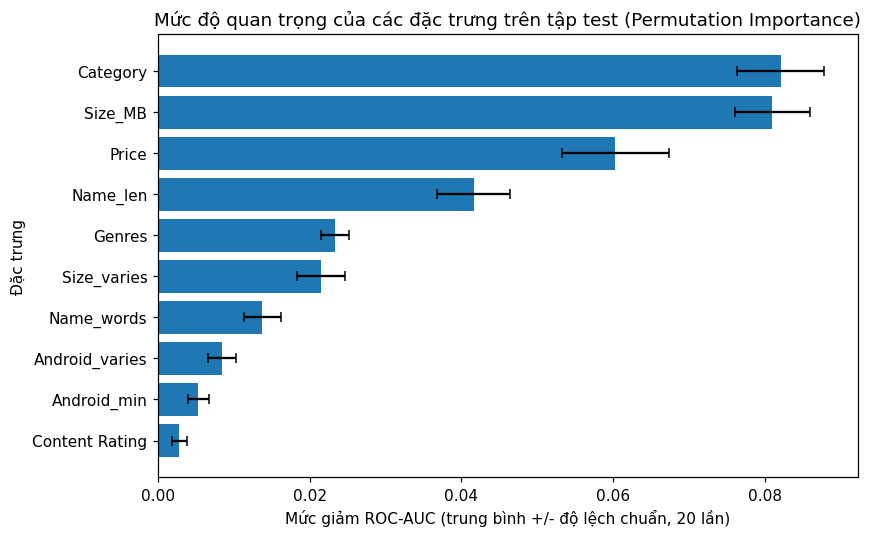

In [9]:
perm = permutation_importance(
    best_est, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=42
)
imp = pd.DataFrame({
    "mean": perm.importances_mean,
    "std": perm.importances_std
}, index=X_test.columns).sort_values("mean")

display(imp.sort_values("mean", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], capsize=3)
ax.set_title("Mức độ quan trọng của các đặc trưng trên tập test (Permutation Importance)")
ax.set_xlabel("Mức giảm ROC-AUC (trung bình +/- độ lệch chuẩn, 20 lần)")
ax.set_ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

In [10]:
feature_comparison = pd.DataFrame([
    {
        "Nhóm đặc trưng": "Chỉ đặc trưng kỹ thuật",
        "ROC-AUC": tech_roc_auc,
        "PR-AUC": tech_pr_auc
    },
    {
        "Nhóm đặc trưng": "Toàn bộ đặc trưng (HistGradientBoosting)",
        "ROC-AUC": test_scores.loc["HistGradientBoosting", "ROC-AUC"],
        "PR-AUC": test_scores.loc["HistGradientBoosting", "PR-AUC"]
    }
])
display(feature_comparison.round(4))

,Nhóm đặc trưng,ROC-AUC,PR-AUC
0,Chỉ đặc trưng kỹ thuật,0.7697,0.6823
1,Toàn bộ đặc trưng (HistGradientBoosting),0.8575,0.7941


- Ba đặc trưng làm giảm ROC-AUC nhiều nhất khi xáo trộn là `Category` (0,0821), `Size_MB` (0,0810), `Price` (0,0603). Xáo trộn cột `Genres` làm ROC-AUC giảm 0,0233 và đo đóng góp của toàn bộ các thể loại trong cột này.
- Mô hình chỉ dùng đặc trưng kỹ thuật đạt ROC-AUC 0,7697 và PR-AUC 0,6823. Mô hình đầy đủ cao hơn 0,0878 ROC-AUC.
- Kết quả xáo trộn mô tả đóng góp dự báo của các cột trong mô hình đã huấn luyện.

#### **7. Trả lời câu hỏi và giới hạn**

**Trả lời.** Với các thuộc tính mô tả và kỹ thuật, HistGradientBoosting đạt ROC-AUC 0,8575, PR-AUC 0,7941 và F1 0,7107 trên tập kiểm tra chia theo `App`. Mô hình cơ sở đoán lớp đa số đạt ROC-AUC 0,5000, PR-AUC 0,3877 và F1 bằng 0. Ba đặc trưng đóng góp nhiều nhất theo phép xáo trộn là `Category`, `Size_MB` và `Price`.

**Giới hạn**
- Dữ liệu là ảnh chụp tại một thời điểm năm 2018, nên một số thông tin như `Size`, tên app hay `Android Ver` có thể đã được cập nhật sau khi app nổi tiếng, tức là giả định "biết trước lúc phát hành" chỉ mang tính xấp xỉ.
- Mô hình không nắm được sức mạnh thương hiệu hay nhu cầu cộng đồng (dẫn đến bỏ sót `Minecraft` hoặc app tôn giáo), đồng thời hay mặc định sai đối với các app nhẹ <=5 MB (FN 92,5%).
- Kết quả chỉ mang tính dự báo từ tương quan dữ liệu, không có nghĩa là tăng dung lượng hay rút ngắn tên app sẽ giúp tăng lượt tải.
- Ngưỡng phân loại 0,5 và mốc 1 triệu lượt cài là lựa chọn của nhóm; một số danh mục trong tập test có ít mẫu (như `MEDICAL`) nên tỷ lệ lỗi chưa thật sự ổn định.